# Problemas inversos: ajuste, modelo y evidencia

**Pregunta:** Con dos profundidades de fuente posibles, ¿cuánto distingue un perfil gravimétrico de 41 estaciones entre un cuerpo de 100 kg/m³ en la celda somera y el mismo contraste en la celda profunda?

**Nivel 1 · Prerrequisitos: ninguno; lectura estimada: 35 minutos.**

## Objetivos

Comparar dos hipótesis explícitas de profundidad mediante el mismo motor gravimétrico 3D e interpretar la separación como evidencia de sensibilidad.

## Preparación

Use el entorno Python 3.12 fijado. Créelo desde la raíz con `scripts/setup.ps1 -Notebooks` en Windows o `scripts/setup.sh --notebooks` en Linux/macOS. El comando se documenta como referencia; el notebook no instala paquetes.

```text
pip install simpeg==0.25.2 geoana==0.8.1 discretize==0.12.0
```

Importar una vez el método y herramientas gráficas. La celda informa implementación activa.

In [1]:
# Importar métodos del repositorio y herramientas gráficas.
from importlib.metadata import version
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().parents[2]
sys.path.insert(0, str(root / 'data-pipeline'))
import gravity_forward
print('Motor:', gravity_forward.ENGINE)


Motor: simpeg-0.25.2-geoana-0.8.1-f64-ram


## Datos

La entrada es un modelo sintético pequeño, definido aquí: huella horizontal de 100 m × 100 m, dos celdas verticales de 100 m y 41 receptores en z=0 m. No es un levantamiento medido ni un conjunto de datos externo. El cálculo directo usa la implementación del repositorio en `data-pipeline/gravity_forward.py` y el motor fijado SimPEG/Geoana. El código y el experimento son material del producto bajo Apache-2.0. El eje vertical es positivo hacia arriba, el contraste de densidad está en kg/m³ y `gz` predicho es positivo hacia arriba en mGal.

Leer entradas declaradas o construir geometría sintética propia. No se carga salida de solver.

In [2]:
# Definir columna sintética de dos capas y línea superficial exterior.
mesh = {'origin_m': np.array([-50., -50., -300.]), 'hx_m': np.array([100.]),
        'hy_m': np.array([100.]), 'hz_m': np.array([100., 100.]),
        'active': np.array([True, True])}
x = np.linspace(-500., 500., 41)
receivers = np.column_stack([x, np.zeros_like(x), np.zeros_like(x)])
base = {'schema': 'gravity-prism-forward-request-1',
        'frame': dict(gravity_forward.FRAME), 'mesh': mesh,
        'receivers_m': receivers, 'engine': gravity_forward.ENGINE}
print('Celdas:', len(mesh['active']), '| estaciones:', len(receivers))


Celdas: 2 | estaciones: 41


## Método

### El experimento como operador directo

Escribimos d=F(m)+ε, donde m es el contraste de densidad por celda y F incorpora malla, coordenadas receptoras, núcleo gravitacional y convención de signo. Aquí ε vale cero porque esta primera lección aísla el operador determinista; no afirma que el ruido de campo sea nulo. SimPEG ofrece un marco de simulación e inversión, mientras el wrapper del producto fija el motor CPU, geometría de malla, unidades y contrato espacial (Cockett et al., 2015, https://doi.org/10.1016/j.cageo.2015.09.015).

### Por qué mantenemos fijo el experimento

La primera ejecución ubica todo el contraste en la celda somera. La siguiente cambia solo el vector de densidad activa; conserva línea de receptores, malla, motor y marco de coordenadas. Es una comparación controlada: si cambian las predicciones, la causa es el parámetro de modelo modificado. No prueba otras geometrías, campos regionales ni incertidumbre de posición.

### La señal es espacial, no una puntuación escalar

Una observación de campo potencial integra la respuesta del volumen fuente. La distancia atenúa y ensancha la señal, por lo que profundidad puede intercambiarse con amplitud y volumen. Un perfil permite revisar pico, ancho, simetría y colas sin comprimir todo en un ajuste. Los valores que siguen proceden de llamadas reales al operador del producto.

### Límite de evidencia

Ambos modelos son entradas del mismo solver directo; ninguno es una estimación inversa. Un solapamiento mostraría baja discriminación para esta adquisición y parametrización, no que la Tierra contenga cualquiera de los dos cuerpos. Una diferencia mostraría sensibilidad en esta geometría lineal, no unicidad 3D. El control no incluye ruido, topografía, tendencia regional ni exclusión de estaciones.

### Qué puede sostener el primer resultado

La respuesta numérica informa escala de predicción y separación entre perfiles. Sirve para evaluar si una adquisición podría distinguir estas dos hipótesis concretas. No calibra ruido ni selecciona geología preferida. Para sostener esa inferencia hacen falta observaciones, errores declarados, información previa, selección de candidatos y evaluación independiente.

Ubicar 100 kg/m³ en celda superior y llamar al operador; revisar respuesta central.

In [3]:
# Evalúe la hipótesis de fuente somera.
shallow_result = gravity_forward.forward_gravity({**base, 'density_kg_m3': np.array([0.0, 100.0])})
print('resultado_somero: gz central =', float(shallow_result['gz_up_mgal'][len(x) // 2]), 'mGal')

resultado_somero: gz central = -0.02927236040238318 mGal


Mover el contraste a celda inferior. La adquisición fija aísla profundidad.

In [4]:
# Evalúe la hipótesis de fuente profunda.
deep_result = gravity_forward.forward_gravity({**base, 'density_kg_m3': np.array([100.0, 0.0])})
print('resultado_profundo: gz central =', float(deep_result['gz_up_mgal'][len(x) // 2]), 'mGal')

resultado_profundo: gz central = -0.010659464525418208 mGal


Reducir contraste somero a la mitad para exponer intercambio amplitud-profundidad; no es inversión.

In [5]:
# Evalúe la hipótesis con la mitad del contraste somero.
half_result = gravity_forward.forward_gravity({**base, 'density_kg_m3': np.array([0.0, 50.0])})
print('resultado_mitad: gz central =', float(half_result['gz_up_mgal'][len(x) // 2]), 'mGal')

resultado_mitad: gz central = -0.01463618020119159 mGal


Graficar resultados reales del solver y diferencia por profundidad. Leer amplitud y ancho conjuntamente.

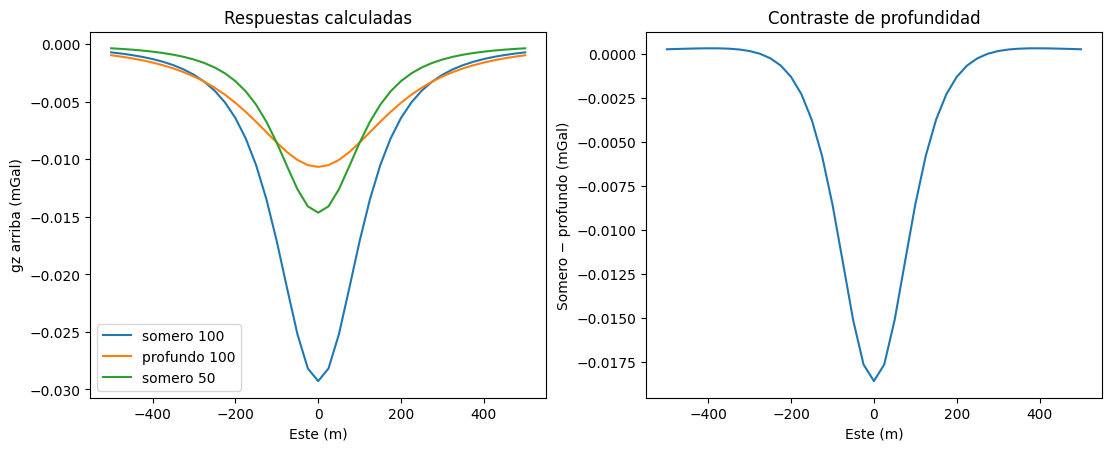

In [6]:
# Comparar hipótesis calculadas sin ajuste ni suavizado.
fig, (ax, dx) = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
for result, label in ((shallow_result, 'somero 100'), (deep_result, 'profundo 100'), (half_result, 'somero 50')):
    ax.plot(x, result['gz_up_mgal'], label=label)
dx.plot(x, shallow_result['gz_up_mgal'] - deep_result['gz_up_mgal'])
ax.set(xlabel='Este (m)', ylabel='gz arriba (mGal)', title='Respuestas calculadas')
dx.set(xlabel='Este (m)', ylabel='Somero − profundo (mGal)', title='Contraste de profundidad')
ax.legend()
plt.show()

La figura superpone los perfiles de gravedad vertical calculados y muestra su diferencia con signo. El panel izquierdo hace visible el cambio de amplitud y ancho asociado a la profundidad; el derecho indica dónde la línea es más sensible a este intercambio concreto. Las curvas provienen de llamadas separadas al motor del producto. Si son parecidas, indican discriminación limitada para esta geometría, no modelos idénticos ni una solución única.

### Interpretación

Ambos modelos son entradas del mismo solver directo; ninguno es una estimación inversa. Un solapamiento mostraría baja discriminación para esta adquisición y parametrización, no que la Tierra contenga cualquiera de los dos cuerpos. Una diferencia mostraría sensibilidad en esta geometría lineal, no unicidad 3D. El control no incluye ruido, topografía, tendencia regional ni exclusión de estaciones.

## Resultados

**Respuesta:** La diferencia máxima somero–profundo es 0.01861289587696497 mGal; las predicciones centrales son -0.02927236040238318 y -0.010659464525418208 mGal. Es sensibilidad de esta línea, no inversión.

In [7]:
# Informar evidencia de ambos arreglos calculados.
max_difference = float(np.max(np.abs(shallow_result['gz_up_mgal'] - deep_result['gz_up_mgal'])))
print({'max_diferencia_mgal': max_difference,
       'centro_somero_mgal': float(shallow_result['gz_up_mgal'][len(x) // 2]),
       'centro_profundo_mgal': float(deep_result['gz_up_mgal'][len(x) // 2])})

{'max_diferencia_mgal': 0.01861289587696497, 'centro_somero_mgal': -0.02927236040238318, 'centro_profundo_mgal': -0.010659464525418208}


## Resumen

La respuesta directa depende del modelo y la geometría de adquisición declarados. Este par controlado aísla un cambio de modelo y muestra la evidencia de una sola línea gravimétrica. Interprete la separación como sensibilidad. No es inversión, validación de campo ni interpretación geológica.

## Referencias

- https://doi.org/10.1016/j.cageo.2015.09.015